For this task we are given
$$H(X,\theta) = \max(\theta X_1 + X_2, (1 - \theta)X_3)$$
This gives us the derivative where $\mathbb{I}$ is the indicator function
$$
\dfrac{\partial}{\partial \theta} H(X,\theta) = X_1 \mathbb{I}(\theta X_1 + X_2 > (1 - \theta)X_3) - X_3 \mathbb{I}(\theta X_1 + X_2 < (1 - \theta)X_3)
$$
We are given that the shape parameter of the erlang distribution is $k = 2$ and that the mean is 1, 2, 3 for $X_1, X_2, X_3$ respectively. The mean of the erlang distribution is given by $\frac{k}{\lambda}$, so we can solve for the rate parameter $\lambda$ to get $\lambda = 2, 1, \frac{2}{3}$ for $X_1, X_2, X_3$ respectively.

Note that the erlang distribution is a special case of the gamma distribution when the shape parameter is an integer.

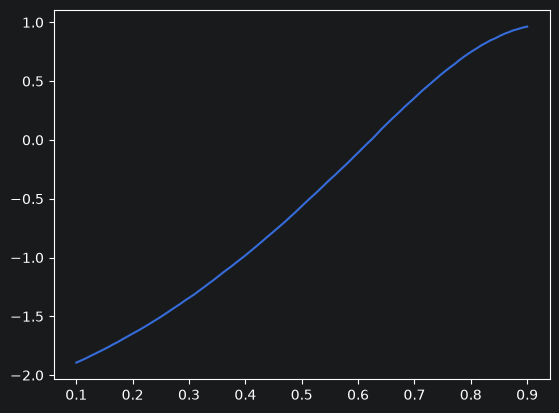

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# scale parameter
N = 100000
beta = np.array([1/2, 1, 3/2])
theta = np.linspace(0.1, 0.9, 100)

X = np.random.gamma( shape = 2,
                 scale= beta[:, None],
                 size= (3, N)
                 )

first_max = lambda x: (x[0] * (theta[:,None] * x[0] + x[1] > (1 - theta[:,None]) * x[2]))

second_max = lambda x: (x[2] * (theta[:,None] * x[0] + x[1] < (1 - theta[:,None]) * x[2]))

# Each row is with respect to a new theta in [0, 0.1, ..., 0..9]
dH = lambda x: first_max(x) - second_max(x)

from week9 import *

l, s = pertubation_analysis_derivative(X, dH)

plt.plot(theta, l)


We now use the score function algorithm instead. We need to compute the score function for the $Erlang_2(\lambda)$ distribution. The probability density function is given by
$$
f(x; \lambda) = \lambda^2 x e^{-\lambda x}
$$
where $\lambda = \dfrac{1}{\beta}$, so we have $\lambda_1 = 2, \lambda_2 = 1, \lambda_3 = \dfrac{2}{3}$. However, this does not depend on $\theta$, so the score function is trivially 0. However, we can define new equivalent random variables such that the score function can be defined as a function of $\theta$.

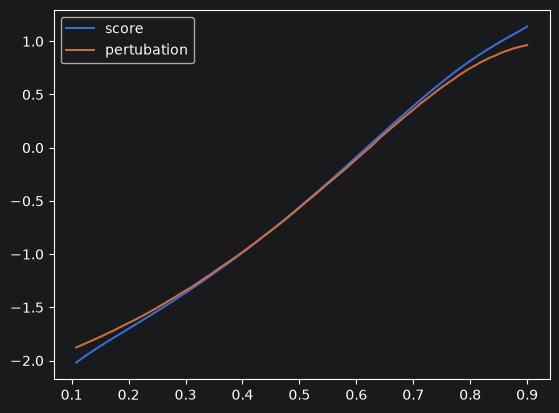

In [22]:
score_func = lambda Q, lam, theta: -2/theta[:, None] + 2/(1-theta[:, None]) + lam[0]*theta[0] / theta[: None]**2 - lam[2]*Q[2] / (1-theta[:, None])**2



lam = [2, 1, 2/3]

sf = lambda Q: score_func(Q, lam, t)
H = lambda Q: np.maximum(Q[0,:] + Q[1,:], Q[2,:])

estimates = []
for t in theta[1:]:

    score_func = lambda Q, lam, t: -2/t + 2/(1-t) + lam[0]*Q[0,:]/ t**2 - lam[2]*Q[2,:] / (1-t)**2

    Q = np.vstack(
        [X[0,:] * t,
        X[1,:],
        X[2, :] * (1-t)
        ]
    )

    estimate, _ = score_function_derivative(Q, h_func= H, score_func= sf)
    estimates.append(estimate)

plt.plot(theta[1:], estimates, label = 'score')
plt.plot(theta[1:], l[1:], label = 'pertubation')
plt.legend()
plt.show()
